# Criteo Uplift Project · 完整学习笔记

学习主线是 **业务问题 → 数据准备 → 分组诊断 → ATE/ITT → 建模 → 验证选型 → Test → 稳定性 → 新人群打分 → 业务规划 → 结论**。

阅读时回答每一步的输入、做什么、输出给谁，不必逐行钻研语法。正式结果来自同一个完整实验。这里读取现成产物，并调用正式指标函数完成一个明确标注的八行教学核验；不重新训练或改写实验结果。

研究问题是在固定触达预算下，怎样识别因广告分配而增加转化的人群。数据只支持公开样本上的离线分析，不等于真实线上广告收入。

In [1]:
from pathlib import Path
import sys, os, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.config import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, HTML
from criteo_uplift.pipeline_io import result_directory
RUN = result_directory(os.environ.get('CRITEO_RUN', 'conversion_1000000_seed42_refactored'), ROOT)
manifest = json.loads((RUN / 'manifest.json').read_text())
assert manifest['status'] == 'complete'
print('结果来源：', RUN.relative_to(ROOT), '｜建模行数：', manifest['sample_n'])
TABLE_STYLES = [
    {'selector': 'th', 'props': [('background-color', '#edf3f8'), ('padding', '8px')]},
    {'selector': 'td', 'props': [('padding', '8px'), ('border-bottom', '1px solid #e3eaf0')]},
]


结果来源： reports/published/conversion_1000000_seed42_refactored ｜建模行数： 1000000


## 01 · 数据范围、质量与样本划分

本页读取已保存的 JSON、CSV 和图片，并进行展示专用的格式化、整合与排版。计算、抽样、划分核验与结果写入由 `criteo_uplift` 和主运行流程完成；修改本页的标题、选列或样式不会回写实验产物。

阅读顺序：**分析边界 → 数据质量 → 全量与抽样构成 → 样本划分 → 重叠检查**。表头与类别使用英文，说明和代码注释使用中文。

## 1. 数据集

- **f0–f11**：12 个匿名处理前特征，作为模型输入。
- **treatment**：处理分配；不等于实际广告曝光。
- **conversion / visit**：结果指标；**exposure** 仅用于审计，不加入模型特征，也不用于筛选人群。

公开数据不含可靠用户标识。`row_id` 标识原 CSV 的来源行，不代表用户身份；本页的数量均为行数。当前结果针对公开样本的分配效果，不直接等于线上曝光效果或收益。

In [2]:
# 只读取审计与抽样说明；本页不加载原始 CSV 或样本缓存。
audit = json.loads((RUN / "data_preparation/audit.json").read_text())
sample_report = json.loads((RUN / "data_preparation/sample_report.json").read_text())
print("分析指标：", manifest["primary_outcome"], "｜抽样随机种子：", sample_report["seed"])
print("抽样方法：", {"all rows": "保留全部来源行", "uniform without replacement, random-priority reservoir": "均匀无放回抽样（随机优先级蓄水池）"}.get(sample_report["sampling"], sample_report["sampling"]))
print("建模特征精度：", sample_report["feature_representation"], "｜原始字段数：", audit["n_columns"])

分析指标： conversion ｜抽样随机种子： 42
抽样方法： 均匀无放回抽样（随机优先级蓄水池）
建模特征精度： float32 ｜原始字段数： 16


## 2. 全量数据质量：有没有基础异常？

只展示缺失、非法标签和标签逻辑异常。以下计数直接来自全量审计；缺失与非法标签按单元格计数，逻辑异常按行计数。

In [3]:
# 每个检查只展示一次；保留原始计数，不在 Notebook 中重做校验。
quality_fields = {
    "missing_or_nonfinite": "Missing / non-finite values",
    "invalid_binary_labels": "Invalid binary-label values",
    "control_exposed": "Control rows with exposure",
    "conversion_without_visit": "Conversions without visit",
}
quality_table = pd.DataFrame([
    {"Check": label, "Count": audit[key]} for key, label in quality_fields.items()
])
display(quality_table.style.hide(axis="index").format({"Count": "{:,.0f}"}).set_table_styles(TABLE_STYLES))


Check,Count
Missing / non-finite values,0
Invalid binary-label values,0
Control rows with exposure,0
Conversions without visit,0


### 完整记录重复指纹：多余行数与分母

重复指纹使用原始精度下的完整记录字段，属于内容重复候选，不能证明同一用户重复出现，也不据此自动删除。全量内部的内容重复与后文的跨集合特征匹配是不同检查。

同一指纹出现 k 次只计 k−1 个多余行，不能把这个数理解成“唯一重复记录种数”。具体计数定义、分母和指纹局限直接来自审计文件。

In [4]:
# 直接读取审计字段；比例和方法说明由扫描阶段生成。
duplicate_table = pd.DataFrame([
    {"Item": "Full source rows", "Value": f"{audit['n_rows']:,}"},
    {"Item": "Excess fingerprint rows", "Value": f"{audit['duplicate_row_fingerprints']:,}"},
    {"Item": "Excess fraction", "Value": f"{audit['duplicate_row_fraction']:.2%}"},
    {"Item": "Fraction denominator (rows)", "Value": f"{audit['duplicate_fraction_denominator']:,}"},
    {"Item": "Count definition", "Value": audit["duplicate_count_definition"]},
    {"Item": "Fingerprint method / limitations", "Value": audit["duplicate_method"]},
])
display(duplicate_table.style.hide(axis="index").set_table_styles(TABLE_STYLES).set_properties(
    subset=["Value"], **{"text-align": "left", "white-space": "normal", "max-width": "620px", "overflow-wrap": "anywhere"}
))


Item,Value
Full source rows,"13,979,592"
Excess fingerprint rows,"1,259,545"
Excess fraction,9.01%
Fraction denominator (rows),"13,979,592"
Count definition,多余行数 = 全量行数 - 不同完整行指纹数；同一指纹出现 k 次贡献 k-1 行。不是出现重复的不同记录种数，也不是所有参与重复的行数；比例分母为全量原始记录数。
Fingerprint method / limitations,对原始 CSV 的全部 16 个字段按 float64 表示，使用 pandas.util.hash_pandas_object(index=False) 生成 uint64 指纹，并跨全部分块统计不同指纹数。64 位哈希存在碰撞可能，float64 解析也不等于原始文本逐字节相等；仅识别内容重复候选。没有可靠用户标识，不能证明同一用户重复出现，不据此自动删除记录。


## 3. 全量与建模样本：分组不均衡与稀疏转化

用一张对照表回答两个问题：处理／对照比例有多不均衡，转化事件有多稀少。`Share` 的分母为所在数据集总行数；`Conversion rate` 的分母为该组行数。全量和建模样本各自的 `Total` 已由计算阶段保存。

主流程按块扫描原始 CSV，统一准备全量审计、建模抽样和诊断统计。建模样本采用随机优先级蓄水池的均匀无放回抽样；C2ST 则独立按组等量抽样，用来比较两组特征分布。建模样本缓存与全量审计缓存分别核验来源和配置。原始统计使用 float64，建模特征缓存使用 float32 以降低内存；两者用途和重叠检查口径需要区分。

In [5]:
# 仅拼接两份现成汇总；组别标签由数据生成阶段统一。
group_table = pd.concat([
    pd.DataFrame(report["group_summary"]).assign(Dataset=label)
    for label, report in (("Full source", audit), ("Modeling sample", sample_report))
], ignore_index=True)
group_table = group_table[["Dataset", "group", "n", "fraction", "conversion_positive", "conversion_rate"]].rename(columns={
    "group": "Group", "n": "Rows", "fraction": "Share",
    "conversion_positive": "Conversions", "conversion_rate": "Conversion rate",
})
display(group_table.style.hide(axis="index").format({
    "Rows": "{:,.0f}", "Share": "{:.2%}", "Conversions": "{:,.0f}", "Conversion rate": "{:.4%}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["Conversion rate"], **{"font-weight": "600", "color": "#175c83"}))

Dataset,Group,Rows,Share,Conversions,Conversion rate
Full source,Control,"2,096,937",15.00%,"4,063",0.1938%
Full source,Treatment,"11,882,655",85.00%,"36,711",0.3089%
Full source,Total,"13,979,592",100.00%,"40,774",0.2917%
Modeling sample,Control,"149,589",14.96%,273,0.1825%
Modeling sample,Treatment,"850,411",85.04%,"2,609",0.3068%
Modeling sample,Total,"1,000,000",100.00%,"2,882",0.2882%


### 建模特征分布

下图读取运行阶段保存的图片，展示各匿名特征的取值分布；纵轴使用对数刻度。本页不重新加载百万行样本或执行直方图分箱。处理组与对照组的 SMD／KS 检查统一放在 本笔记后续章节。

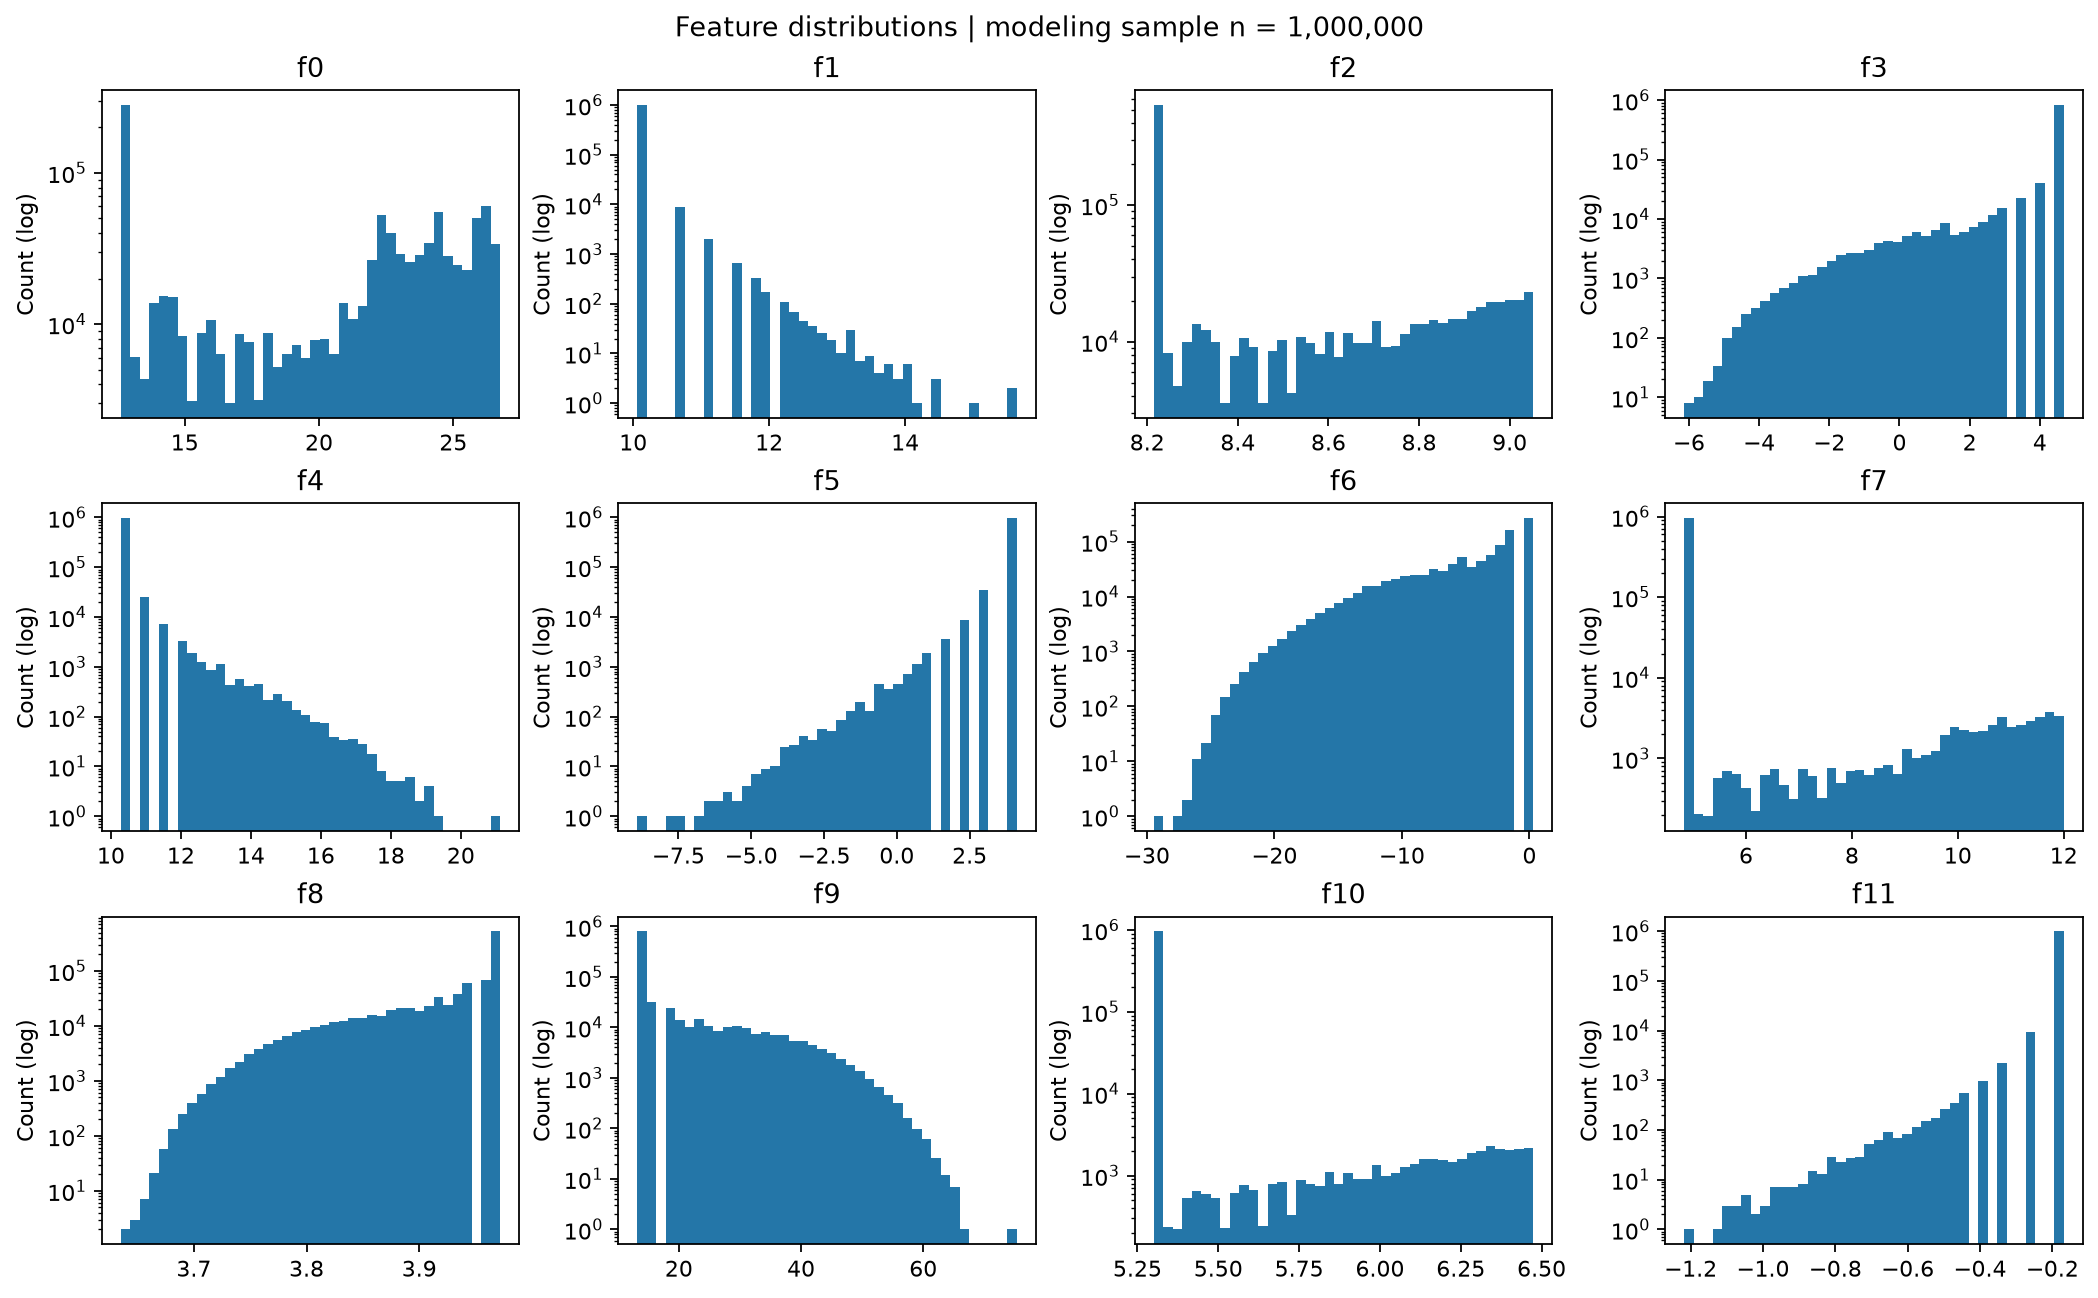

In [6]:
# 只显示当前实验的图片；缺失时明确提示，不自动计算或借用其他实验的结果。
feature_plot = RUN / "figures/sample_features.png"
if feature_plot.is_file():
    display(Image(filename=str(feature_plot)))
else:
    print("该实验尚未保存特征分布图；本页跳过此图，不触发计算。")

## 4. 样本划分：各集合是否保留足够事件？

主流程按 `treatment × 主结果` 联合分层，划分训练／验证／测试集（60%／20%／20%）。下表只展示各集合、各组的规模和事件数，不重复总体占比与转化率。

训练集用于拟合，验证集用于选择，测试集用于冻结后的独立评价；本页不重新划分数据。

In [7]:
# 展示已保存的划分汇总；隐藏 DataFrame 默认索引。
split_table = pd.read_csv(RUN / "data_preparation/split_summary.csv")
split_table = split_table.rename(columns={
    "split": "Split", "treatment": "Group", "n": "Rows",
    "conversion_positive": "Conversions", "visit_positive": "Visits",
})
split_table["Split"] = split_table["Split"].replace({"train": "Train", "validation": "Validation", "test": "Test"})
split_table["Group"] = split_table["Group"].replace({0: "Control", 1: "Treatment"})
display(split_table.style.hide(axis="index").format({
    "Rows": "{:,.0f}", "Conversions": "{:,.0f}", "Visits": "{:,.0f}",
}, na_rep="—").set_table_styles(TABLE_STYLES))

Split,Group,Rows,Conversions,Visits
Train,Control,"89,754",164,"3,372"
Train,Treatment,"510,246","1,565","24,685"
Validation,Control,"29,917",54,"1,064"
Validation,Treatment,"170,083",522,"8,310"
Test,Control,"29,918",55,"1,113"
Test,Treatment,"170,082",522,"8,324"


## 5. 跨集合核验：来源行与匿名特征分开解释

**来源行核验**检查行号非空唯一、集合间互斥、划分覆盖完整样本。**特征匹配**检查不同集合中相同的匿名特征表示；匹配比例的分母是被检查集合的行数。

当前建模表示为 `float32`，舍入可能增加匹配数量；原始 `float64` 与建模表示的比较属于精度敏感性分析。来源行不同、特征相同，都不能确定是否为同一用户。此页只展示当前结果文件实际记录的检查，不把历史研究数字当作当前实验的新结果。敏感性分析见 本笔记后续章节。

In [8]:
# 读取已保存的核验结论；旧实验未记录的检查不视为已通过。
overlap = json.loads((RUN / "data_preparation/feature_overlap.json").read_text())
check_labels = {"non_null_unique": "Non-null and unique", "pairwise_disjoint": "Pairwise disjoint", "complete_coverage": "Complete coverage"}
checks = overlap.get("row_id_checks", {})
print("来源行核验：", "；".join(
    f"{label}: " + {True: "Pass", False: "Fail", None: "Not recorded"}[checks.get(key)]
    for key, label in check_labels.items()
))
overlap_rows = [
    {"Checked split": name.capitalize(), "Reference split": "Train", "Feature match rate": fraction}
    for name, fraction in overlap["fraction_matching_training_features"].items()
]
if "fraction_test_matching_validation_features" in overlap:
    overlap_rows.append({"Checked split": "Test", "Reference split": "Validation", "Feature match rate": overlap["fraction_test_matching_validation_features"]})
display(pd.DataFrame(overlap_rows).style.hide(axis="index").format({"Feature match rate": "{:.3%}"}).set_table_styles(TABLE_STYLES))

来源行核验： Non-null and unique: Pass；Pairwise disjoint: Pass；Complete coverage: Pass


Checked split,Reference split,Feature match rate
Validation,Train,1.858%
Test,Train,1.856%
Test,Validation,0.615%


In [9]:
# 来源指纹只展示一次，用于确认本页读取的实验来源。
print("来源 SHA256：", manifest["source"]["sha256"])

来源 SHA256： e4d7c710ca1f38e523309d0f8a0745d1b53e7392d51f20d1088b6cfeaef222ef


## 02 · 实验可信度诊断与平均处理效应

本页读取统计产物，可以重新排版表格与绘制图表；单位转换、坐标轴和颜色只用于展示，不重新执行检验、置换、模型训练或结果写入。正文及注释使用中文，表格使用英文标签并隐藏默认索引。

**阅读顺序：平均效果 → 分配比例 → 单变量平衡 → 联合可区分性 → 结果可学习性。** 每个表只回答一个问题，共用的范围、样本量和计算精度在表外说明一次。

## 1. 全量平均效果：差异有多大，区间有多宽？

读取 `evaluation/ate_summary.csv（scope=full_dataset）`。ATE 是处理组结果率减去对照组结果率；表中差值与区间采用百分点（pp），两组结果率及相对提升采用百分比。图表恢复历史双子图设计，两个横轴分别缩放且保留零效应参考；粗区间线、大端点及小空心点帮助辨认较窄的 Visit 区间。

这是全量公开样本的描述性实验背景，不用于模型选择。P 值由同一双侧 pooled z 检验的稳定对数尾概率计算，科学计数文本约保留四位有效数字。`ln(P)` 保存自然对数；普通浮点 P 值下溢为零时，仍可用对数值表达量级，不能把它解释为真实概率为零。

Outcome,Control rate,Treatment rate,ATE (pp),95% CI (pp),Relative uplift,P-value,ln(P)
Conversion,0.1938%,0.3089%,+0.1152,"[+0.1085, +0.1219]",+59.45%,7.308e-179,-410.174
Visit,3.8201%,4.8543%,+1.0342,"[+1.0056, +1.0629]",+27.07%,4.387e-927,-2133.018


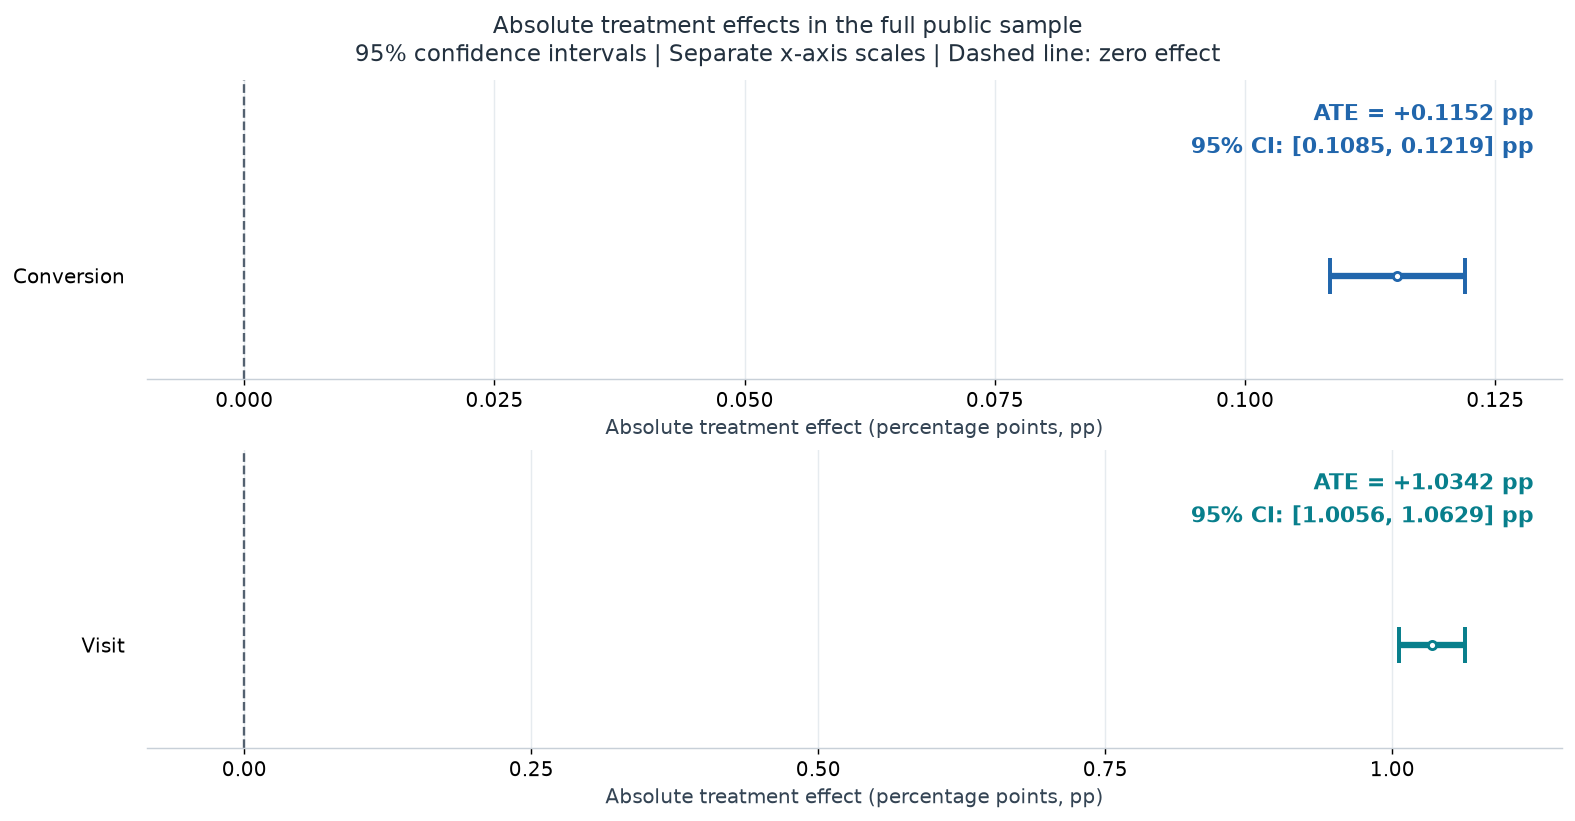

In [10]:
# 只转换显示单位并格式化，原始结果表保持不变。
ate = pd.read_csv(RUN / "evaluation/ate_summary.csv", dtype={"p_value_text": "string"})
ate = ate.loc[ate.scope == "full_dataset"]
ate_table = pd.DataFrame({
    "Outcome": ate["outcome"].str.capitalize(),
    "Control rate": ate["response_control"], "Treatment rate": ate["response_treatment"],
    "ATE (pp)": ate["ate"] * 100,
    "95% CI (pp)": [f"[{lo * 100:+.4f}, {hi * 100:+.4f}]" for lo, hi in zip(ate["ci_low"], ate["ci_high"])],
    "Relative uplift": ate["relative_uplift"], "P-value": ate["p_value_text"],
    "ln(P)": ate["log_p_value"],
})
display(ate_table.style.hide(axis="index").format({
    "Control rate": "{:.4%}", "Treatment rate": "{:.4%}", "ATE (pp)": "{:+.4f}",
    "Relative uplift": "{:+.2%}", "ln(P)": "{:.3f}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["95% CI (pp)"], **{"white-space": "nowrap"}))
# 从当前表格现场绘图；原始列保持比例单位，绘图副本转换为百分点（pp）。
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

ate_plot = (
    ate.set_index('outcome')
    .loc[['conversion', 'visit'], ['ate', 'ci_low', 'ci_high']]
    .mul(100) #转换成pp值
)

with plt.rc_context( # 使用with:设置临时的图片样式参数
    {
        'font.family': 'DejaVu Sans',
        'font.size': 11,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'axes.spines.left': False,
        'axes.edgecolor': '#C8D0D8',
        'axes.labelcolor': '#344454',
        'text.color': '#23313F',
        'figure.facecolor': 'white',
        'axes.facecolor': 'white',
    }
):
    fig, axes = plt.subplots(
        2,
        1,
        figsize=(12, 6.2),
        sharex=False,
        dpi=130,
        constrained_layout=True,
    )
    fig.suptitle(
        'Absolute treatment effects in the full public sample\n'
        '95% confidence intervals | Separate x-axis scales | Dashed line: zero effect',
        fontsize=13,
    )

    for ax, (outcome, row), color in zip(
        axes,
        ate_plot.iterrows(),
        ['#2166AC', '#087F8C'],
    ):
        ax.axvline(
            0,
            color='#536170',
            linestyle='--',
            linewidth=1.3,
            zorder=2,
        )
        ax.errorbar(
            x=[row['ate']],
            y=[0],
            xerr=[
                [row['ate'] - row['ci_low']],
                [row['ci_high'] - row['ate']],
            ],
            fmt='none',
            color=color,
            elinewidth=3.5,
            capsize=10,
            capthick=2.2,
            zorder=3,
        )

        # 单独绘制小型空心点，避免较窄的 Visit 区间被实心标记遮挡。
        ax.plot(row['ate'], 0, marker='o', markersize=4.5,
                markerfacecolor='white', markeredgecolor=color,
                markeredgewidth=1.6, linestyle='none', zorder=4)

        # 每个子图独立缩放，但始终包含零点、点估计和完整 CI；保持线性坐标。
        left = min(0.0, row['ci_low'], row['ate'])
        right = max(0.0, row['ci_high'], row['ate'])
        span = right - left
        padding = 0.08 * span if span > 0 else 0.01
        ax.set_xlim(
            left - padding,
            right + padding,
        )

        ax.set_ylim(-0.45, 0.85)
        ax.set_yticks(
            [0],
            [outcome.capitalize()],
        )
        ax.tick_params(axis='y', length=0, pad=12)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
        
        ax.set_xlabel('Absolute treatment effect (percentage points, pp)')
        ax.set_axisbelow(True)
        ax.grid(axis='x', color='#E6EBEF', linewidth=0.8)

        # 标注使用绘图区相对坐标，放在点和 CI 上方，避免遮挡。
        ax.text(
            0.98,
            0.94,
            f"ATE = {row['ate']:+.4f} pp\n"
            f"95% CI: [{row['ci_low']:.4f}, {row['ci_high']:.4f}] pp",
            transform=ax.transAxes,
            ha='right',
            va='top',
            fontsize=12,
            fontweight='bold',
            color=color,
            linespacing=1.5,
        )

    plt.show()


## 2. 分配比例：公开计数是否接近外部参考？

读取 `srm.json`。85% 是发布数据的外部参考比例，并非已知的原始实验设计参数。这里的显著或不显著均不能直接证明原始线上实验是否通过 SRM 或随机化。

In [11]:
# 样本量与范围只说明一次，表内聚焦观测比例、参考比例与检验结果。
srm = json.loads((RUN / "diagnostics/srm.json").read_text())
print(f"分析范围：全量公开数据｜Control：{srm['n_control']:,} 行｜Treatment：{srm['n_treatment']:,} 行")
srm_table = pd.DataFrame([srm])[["observed_ratio", "expected_ratio", "chi2", "pvalue", "status"]].rename(columns={
    "observed_ratio": "Observed treatment share", "expected_ratio": "Reference share",
    "chi2": "Chi-square", "pvalue": "P-value", "status": "Status",
})
display(srm_table.style.hide(axis="index").format({
    "Observed treatment share": "{:.6%}", "Reference share": "{:.2%}", "Chi-square": "{:.3e}", "P-value": "{:.3e}",
}, na_rep="—").set_table_styles(TABLE_STYLES))
print("参考资料：", srm["reference_source"])

分析范围：全量公开数据｜Control：2,096,937 行｜Treatment：11,882,655 行


Observed treatment share,Reference share,Chi-square,P-value,Status
85.000013%,85.00%,1.818e-06,9.989e-01,computed


参考资料： https://arxiv.org/html/2111.10106#S3


## 3. 单变量平衡：哪些特征存在分布差异？

读取 `balance.csv`；范围与上节相同，使用原始 CSV 的 `float64` 表示。样本量、范围、精度和指纹不再逐特征重复列出。

SMD 用两组均值差除以组内方差的合并尺度，表示标准化后的平均差；KS D 比较两组经验分布函数的最大距离，能反映均值以外的分布差异。

表格按已保存的 `|SMD|` 排序，只保留两组均值、带方向的 SMD、KS 的 **D 统计量**及辅助 P 值。D 是经验分布函数的最大距离，不是乘以根号样本量后的量。大样本下优先看差异大小；KS P 值未经多重校正，不能仅凭显著性判定实际重要性。

In [12]:
# 选取与特征直接相关的列；排序只改变展示顺序，不重新计算统计量。
balance = pd.read_csv(RUN / "diagnostics/balance.csv")
balance_table = balance.sort_values("abs_smd", ascending=False)[[
    "feature", "mean_control", "mean_treatment", "smd", "ks_statistic", "ks_pvalue",
]].rename(columns={
    "feature": "Feature", "mean_control": "Control mean", "mean_treatment": "Treatment mean",
    "smd": "SMD", "ks_statistic": "KS D", "ks_pvalue": "KS P-value",
})
display(balance_table.style.hide(axis="index").format({
    "Control mean": "{:.5f}", "Treatment mean": "{:.5f}", "SMD": "{:+.6f}", "KS D": "{:.6f}", "KS P-value": "{:.3e}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["SMD", "KS D"], **{"font-weight": "600", "color": "#175c83"}))

Feature,Control mean,Treatment mean,SMD,KS D,KS P-value
f3,4.23282,4.16941,-0.048836,0.013794,5.007e-295
f6,-3.99988,-4.18279,-0.040448,0.013069,7.419e-265
f5,4.03934,4.02660,-0.030557,0.006099,5.198e-58
f9,15.88625,16.05259,+0.024001,0.007125,5.184e-79
f1,10.06794,10.07034,+0.023994,0.002662,2.119e-11
f8,3.93465,3.93339,-0.022433,0.008334,5.837e-108
f7,5.08028,5.10556,+0.021270,0.006099,5.198e-58
f10,5.33190,5.33366,+0.010563,0.002415,1.882e-09
f4,10.33653,10.33925,+0.007966,0.002412,1.959e-09
f0,19.65170,19.61476,-0.006866,0.008950,1.913e-124


## 4. 联合可区分性：模型能否区分两组？

C2ST 从全量来源按组等概率无放回抽样，构造两组等量的诊断样本；它不等于建模样本，也不使用正式测试集选模。

固定分类器为标准化 Logistic 与 XGBoost（30 棵树、最多 15 个叶节点，直方图训练）。`binary:logistic` 是树模型内部优化目标，外部检验统计量仍为留出 ROC-AUC；辅助保留 Log loss、Brier 和 AP。内部训练／留出各自置换 treatment，并完整重拟合固定分类器。关注留出 AUC 与 Holm 校正后的 P 值：AUC 的随机基准为 0.5；不显著不证明联合分布相同，显著也不能单独证明随机化失败。

诊断样本：Control 10,000 行 + Treatment 10,000 行；内部训练／留出为 70%／30%。
随机种子：42｜完整重拟合置换：499 次｜P 值分辨率：0.0020｜两模型 Holm 校正。
Dummy 基线对所有行输出内部训练集的 Treatment 占比；这里只展示预测指标，不进行额外检验。


Model,Holdout ROC AUC,Permutation P-value,Holm P-value,Log loss,Brier,AP
dummy,0.5000,—,—,0.69315,0.25000,0.5000
logistic,0.5177,0.006,0.012,0.69253,0.24969,0.5188
xgboost,0.5008,0.446,0.446,0.69497,0.25087,0.5025


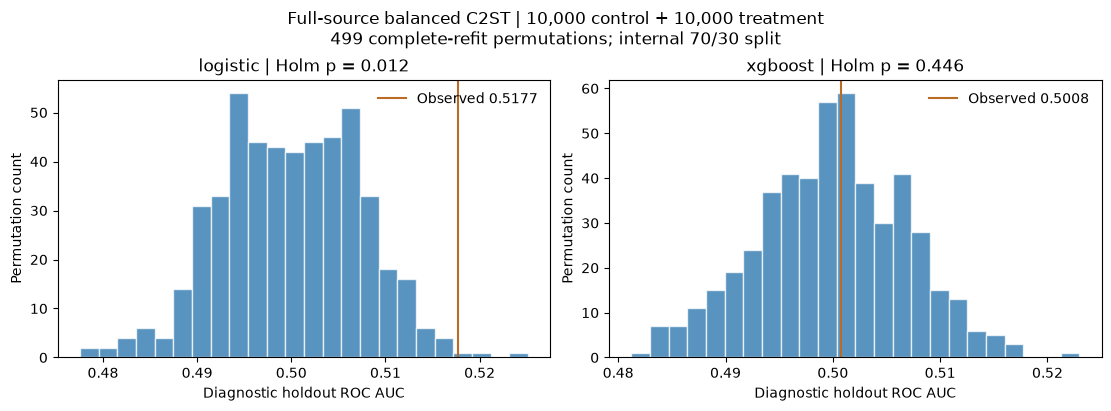

In [13]:
# 共用的抽样与置换配置只在表外展示；表内每行只保留模型自身结果。
c2st = pd.read_csv(RUN / "diagnostics/c2st.csv")
details = json.loads((RUN / "diagnostics/c2st_details.json").read_text())
print(f"诊断样本：Control {details['n_control']:,} 行 + Treatment {details['n_treatment']:,} 行；内部训练／留出为 70%／30%。")
print(f"随机种子：{details['seed']}｜完整重拟合置换：{details['permutations']:,} 次｜P 值分辨率：{details['pvalue_resolution']:.4f}｜两模型 Holm 校正。")
c2st_table = c2st[["model", "roc_auc", "pvalue", "pvalue_holm", "log_loss", "brier", "average_precision"]].rename(columns={
    "model": "Model", "roc_auc": "Holdout ROC AUC", "pvalue": "Permutation P-value", "pvalue_holm": "Holm P-value",
    "log_loss": "Log loss", "brier": "Brier", "average_precision": "AP",
})
# 常数预测基线：前三项指标已保存；常数评分的 AP 等于已保存的留出集正例比例。
# 基线只用于比较预测表现，不新增置换检验或参与两模型的 Holm 校正。
baseline = c2st.iloc[0]
baseline_table = pd.DataFrame([{
    "Model": "dummy",
    "Holdout ROC AUC": baseline["dummy_roc_auc"],
    "Permutation P-value": float("nan"),
    "Holm P-value": float("nan"),
    "Log loss": baseline["dummy_log_loss"],
    "Brier": baseline["dummy_brier"],
    "AP": baseline["test_treatment_ratio"],
}])
c2st_table = pd.concat([baseline_table, c2st_table], ignore_index=True)
print("Dummy 基线对所有行输出内部训练集的 Treatment 占比；这里只展示预测指标，不进行额外检验。")
display(c2st_table.style.hide(axis="index").format({
    "Holdout ROC AUC": "{:.4f}", "Permutation P-value": "{:.3f}", "Holm P-value": "{:.3f}", "Log loss": "{:.5f}", "Brier": "{:.5f}", "AP": "{:.4f}",
}, na_rep="—").set_table_styles(TABLE_STYLES))
# 直接从原来的 c2st_null.csv 现场绘制置换零分布。
null = pd.read_csv(
    (RUN / 'diagnostics' / 'c2st_null.csv')
)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(
    1, 2, figsize=(11, 4), constrained_layout=True,
)
for ax, row in zip(axes, c2st.itertuples()):
    ax.hist(
        null.loc[null['model'] == row.model, 'roc_auc'],
        bins=24, color='#2171ad', alpha=.75, edgecolor='white',
    )
    ax.axvline(
        row.roc_auc, color='#ba6b24', label=f'Observed {row.roc_auc:.4f}',
    )
    ax.set_title(f'{row.model} | Holm p = {row.pvalue_holm:.3f}')
    ax.set_xlabel('Diagnostic holdout ROC AUC')
    ax.set_ylabel('Permutation count')
    ax.legend(frameon=False)
fig.suptitle(
    f"Full-source balanced C2ST | {details['n_control']:,} control + "
    f"{details['n_treatment']:,} treatment\n"
    f"{details['permutations']} complete-refit permutations; internal 70/30 split"
)
plt.show()

## 5. 结果可学习性：特征能预测结果吗？

读取 `learnability.csv`，默认查看整个训练／验证集范围（`whole`），按结果指标分别比较 Dummy 与固定模型。可修改下方 `LEARNING_SCOPE` 以查看某个已保存的分组，选项以输出提示为准。

Dummy 只输出训练集正例率，作为没有特征信息的基准；模型在训练集拟合、在验证集评价。ROC AUC／AP 越高越好，Log loss／Brier 越低越好；AP 应结合验证集正例率阅读。结果可预测不等于 CATE 可预测，也不能代替策略增量评价。

In [14]:
# 仅筛选已有范围与结果；各模型共用的样本量和正例率在表外展示。
LEARNING_SCOPE = "whole"
learning = pd.read_csv(RUN / "diagnostics/learnability.csv")
print("已保存的分析范围：", ", ".join(learning["scope"].unique()))
learning_view = learning.loc[learning["scope"] == LEARNING_SCOPE]
if learning_view.empty:
    print("该结果文件没有所选范围，请从上面的范围中选择。")
for outcome in learning_view["outcome"].unique():
    rows = learning_view.loc[learning_view["outcome"] == outcome]
    context = rows.iloc[0]
    print(f"分析指标：{outcome}｜范围：{LEARNING_SCOPE}｜训练 {context['n_train']:,} 行，验证 {context['n_validation']:,} 行")
    print(f"正例率：训练 {context['positive_rate_train']:.4%}，验证 {context['positive_rate_validation']:.4%}")
    table = rows[["model", "roc_auc", "average_precision", "log_loss", "brier", "status"]].rename(columns={
        "model": "Model", "roc_auc": "ROC AUC", "average_precision": "AP", "log_loss": "Log loss", "brier": "Brier", "status": "Status",
    })
    display(table.style.hide(axis="index").format({
        "ROC AUC": "{:.4f}", "AP": "{:.4f}", "Log loss": "{:.5f}", "Brier": "{:.5f}",
    }, na_rep="—").set_table_styles(TABLE_STYLES))

已保存的分析范围： whole, treatment, control
分析指标：visit｜范围：whole｜训练 600,000 行，验证 200,000 行
正例率：训练 4.6762%，验证 4.6870%


Model,ROC AUC,AP,Log loss,Brier,Status
dummy,0.5000,0.0469,0.18919,0.04467,computed
logistic,0.9320,0.4785,0.11161,0.03141,computed
xgboost,0.9443,0.5035,0.10520,0.03015,computed


分析指标：conversion｜范围：whole｜训练 600,000 行，验证 200,000 行
正例率：训练 0.2882%，验证 0.2880%


Model,ROC AUC,AP,Log loss,Brier,Status
dummy,0.5000,0.0029,0.01972,0.00287,computed
logistic,0.9460,0.1926,0.01264,0.00258,computed
xgboost,0.9502,0.2268,0.01212,0.00251,computed


## 解释边界与刷新方式

这些诊断不证明用户级独立、特征生成时点有效、随机化成立或真实投放收益。公开数据经过发布处理，未知用户依赖、实验分块与跨实验结构仍属于限制。不要根据这些已查看的结果反复调整测试集或正式模型选择。

本页不自动生成“通过／失败”的统计结论，也不重复打印前面各表的数据。要重新运行诊断，应在终端明确执行主流程的 `--diagnostics-only` 模式；这会补齐缺失审计字段、统一汇总标签、更新 ATE 尾概率表示，并重做 C2ST／结果可学习性诊断；既有划分、正式模型及 ATE 点估计和区间保持原口径，与重新运行本页展示单元格不同。详见 [项目流程](../docs/PROJECT_PIPELINE.md)。

## S / T / X：算法与基模型分开理解

S-Learner 拟合一个 $\hat\mu(X,T)$；T-Learner 分别拟合 $\hat\mu_0(X)$、$\hat\mu_1(X)$。两者的 CATE 都是 $\hat\mu_1(X)-\hat\mu_0(X)$。

X-Learner 先用两个结果模型构造伪效应，再拟合连续效应回归器：

$$D_0=\hat\mu_1(X_0)-Y_0,\qquad D_1=Y_1-\hat\mu_0(X_1)$$
$$\hat\tau(X)=e\hat\tau_0(X)+(1-e)\hat\tau_1(X)$$

这里 $e$ 沿用训练集 Treatment 占比。X 的 `predict_outcomes()` 返回第一阶段结果模型的概率，`predict()` 返回第二阶段加权效应，二者不能混淆。

`models.make_uplift_model()` 负责组合。正式候选仍是 S＋Logistic、T＋Logistic、T＋XGBoost、X＋XGBoost。树数默认 150，其他树参数保持原配置；Validation 只选候选策略，当前项目没有做早停或超参数搜索。Test 始终不参与选择。

## 03 · 候选 uplift 模型与 validation 选型

## 本页要回答什么

项目有哪些候选模型？模型分数如何进入策略排序？最终策略和 uplift 候选是如何在 validation 上冻结的？

## 代码导航

- 模型定义与工厂：criteo_uplift/models.py 的 make_uplift_model()。
- 训练与冻结选型：criteo_uplift/training_validation.py 的 fit_and_select_models()。
- 排序指标：criteo_uplift/metrics.py 的 ranking_metrics()。
- 结果文件：validation_policies.csv、validation_ranking.csv、selection.json、模型 .joblib 文件、calibration_*.csv。

本页先看候选模型与验证集证据，再看冻结选择。通用 S/T/X learner 原理请查 DSDAHANDBOOK；本页只解释本仓库的实现与结果。

## 候选模型与实现边界

当前候选为 S-Logistic、T-Logistic、T-XGBoost、X-XGBoost；同时比较随机排序与 response propensity 基线。模型类集中在 models.py，训练、验证和冻结选择集中在 training_validation.py。

阅读顺序：先看 models.make_uplift_model() 如何创建模型，再看 training_validation.fit_and_select_models() 如何只用 train 拟合、只用 validation 选择。response propensity 是强基线，不等于 treatment assignment probability。

In [15]:
# 只展示模型类型、训练耗时和常见配置，避免把所有 sklearn 参数铺成一张超宽表。
model_rows = []
for name, info in manifest['models'].items():
    params = info.get('parameters', {}).get('outcome_params', {})
    model_rows.append({
        'model': name,
        'fit_seconds': info.get('seconds'),
        'n_estimators': params.get('n_estimators'),
        'max_depth': params.get('max_depth'),
        'learning_rate': params.get('learning_rate'),
        'C': params.get('C'),
    })
model_table = pd.DataFrame(model_rows).set_index('model')
display(model_table.style.format({'fit_seconds': '{:.2f}'}))

validation = pd.read_csv((RUN / 'models' / 'validation_policies.csv'))
display(validation[['policy', 'budget', 'incremental_per_100k']].sort_values('incremental_per_100k', ascending=False))

,fit_seconds,n_estimators,max_depth,learning_rate,C
model,,,,,
s_logistic,0.46,nan,None,None,None
t_logistic,0.46,nan,None,None,None
t_xgboost,0.80,150.000000,None,None,None
x_xgboost,1.48,150.000000,None,None,None


,policy,budget,incremental_per_100k
5,propensity,0.2,134.930689
1,s_logistic,0.2,133.166833
2,t_logistic,0.2,129.300871
3,t_xgboost,0.2,116.398163
4,x_xgboost,0.2,105.597563
0,random,0.2,25.283487


## 排序指标的实现位置与使用边界

本页读取 validation_ranking.csv、test_ranking.csv 并展示 ranking.png。指标计算在 metrics.py 的 ranking_metrics()、uplift_curve()；测试阶段的结果由 evaluation.py 保存。

项目同时保留 HT 与传统 plug-in / Qini 口径。不要只看一个面积数字，也不要将不同估计口径的面积直接混用。具体公式与理论解释请查 DSDAHANDBOOK；本页关注结果文件里的字段和本项目选型规则。

Validation ranking


,policy,auuc_ht,qini_ht,auuc_plugin,qini_score_traditional
0,s_logistic,0.001261,0.000629,0.001176,0.000469
1,t_logistic,0.001267,0.000635,0.001186,0.000478
2,t_xgboost,0.001073,0.000441,0.001011,0.000327
3,x_xgboost,0.000995,0.000362,0.000934,0.000261


Frozen test ranking


,policy,auuc_ht,qini_ht,auuc_plugin,qini_score_traditional
0,propensity,0.001198,0.000583,0.001137,0.000448
1,s_logistic,0.001196,0.000580,0.001132,0.000444
2,t_logistic,0.001210,0.000595,0.001148,0.000458
3,t_xgboost,0.000972,0.000357,0.000912,0.000256
4,x_xgboost,0.001099,0.000484,0.001057,0.000379


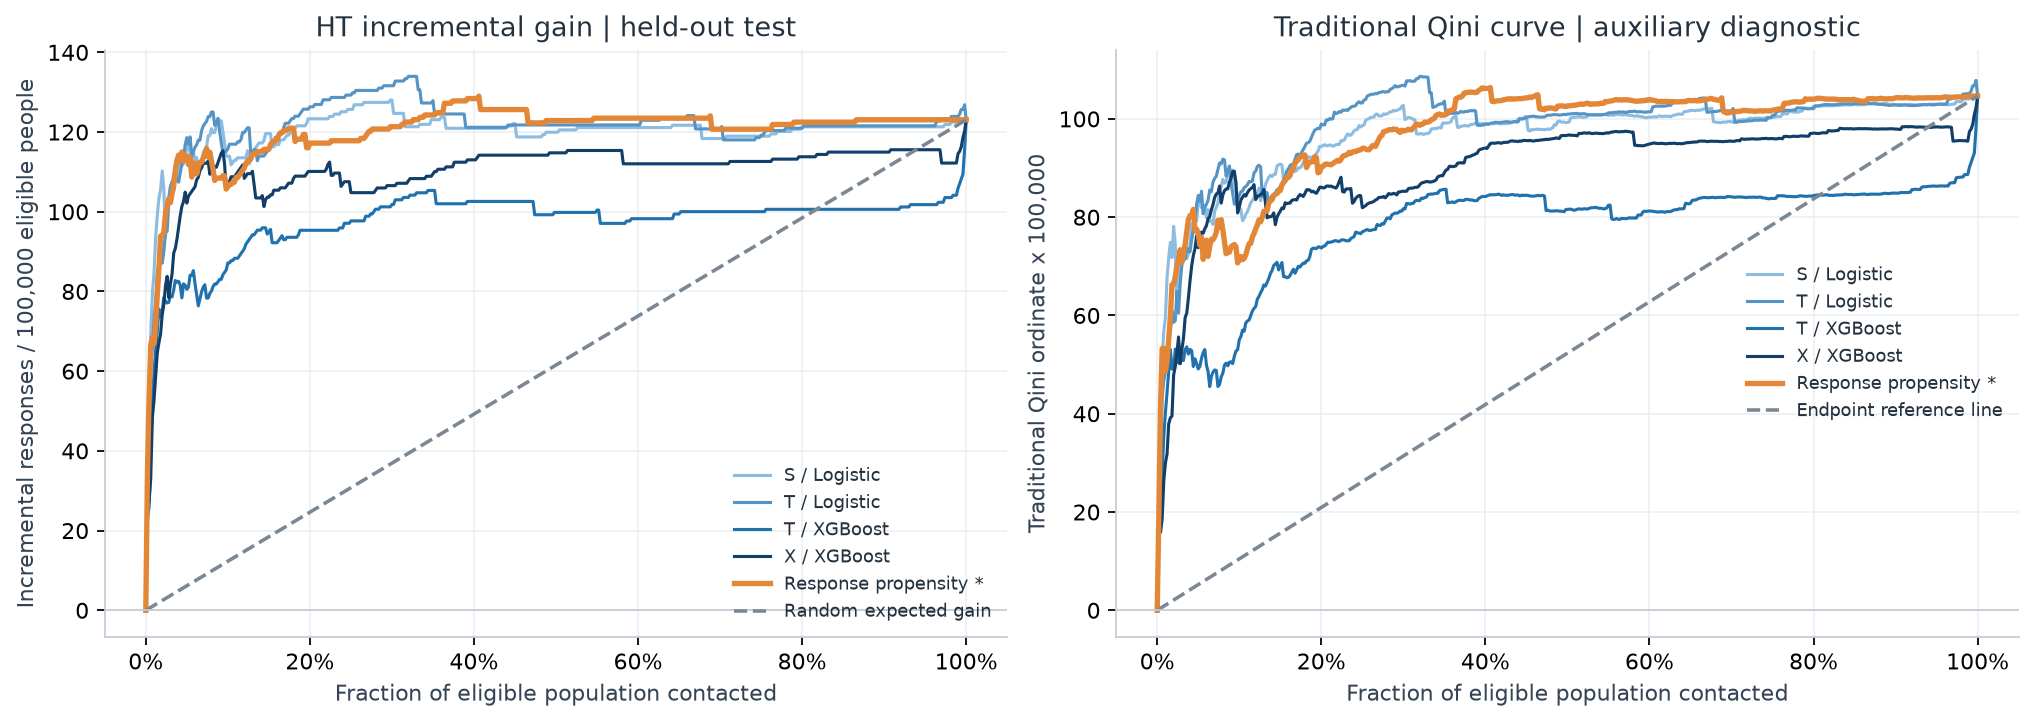

In [16]:
# validation 与 test 排序结果分开展示；test 只用于报告冻结模型的表现，不回头选型。
ranking_columns = [
    'policy', 'auuc_ht', 'qini_ht', 'auuc_plugin',
    'qini_score_traditional', 'relative_lift', 'incremental_per_100k'
]
for label, folder, filename in [
    ('Validation ranking', 'models', 'validation_ranking.csv'),
    ('Frozen test ranking', 'evaluation', 'test_ranking.csv'),
]:
    ranking = pd.read_csv(RUN / folder / filename)
    columns = [column for column in ranking_columns if column in ranking.columns]
    print(label)
    display(ranking[columns].sort_values('policy').reset_index(drop=True))
display(Image(filename=str(RUN / 'figures/ranking.png')))

## CATE 校准诊断

**实现位置：** evaluation.py 的 calibration_table()；测试阶段由 evaluation.py 保存 calibration_*.csv。

分箱结果用于检查预测分数与组间观测差异是否呈现一致趋势。它不是个体真实反事实标签，因此不能据此报告真实 PEHE/ITE MSE；全局均值接近 ATE 也不能证明个体排序正确。测试集诊断不会用于重新校准当前模型。

Validation 冻结的最佳 uplift 候选（不一定是最终策略）: s_logistic


,bin,n,n_treatment,n_control,predicted_cate,prediction_min,prediction_max,observed_ate,standard_error,ci_low,ci_high
0,1,20000,16968,3032,0.000106,0.000045,0.000123,0.000177,0.000102,-0.000023,0.000377
1,2,20000,16974,3026,0.000131,0.000123,0.000139,0.000000,0.000000,0.000000,0.000000
2,3,20000,16938,3062,0.000147,0.000139,0.000154,0.000295,0.000132,0.000036,0.000554
3,4,20000,16890,3110,0.000162,0.000154,0.000170,-0.000262,0.000327,-0.000903,0.000378
4,5,20000,17049,2951,0.000181,0.000170,0.000194,0.000117,0.000083,-0.000045,0.000280
5,6,20000,16973,3027,0.000211,0.000194,0.000233,-0.000095,0.000351,-0.000782,0.000593
6,7,20000,16948,3052,0.000264,0.000233,0.000302,-0.000688,0.000582,-0.001830,0.000454
7,8,20000,16972,3028,0.000362,0.000302,0.000445,0.000471,0.000167,0.000145,0.000798
8,9,20000,17095,2905,0.000675,0.000445,0.001116,0.000898,0.000684,-0.000443,0.002238
9,10,20000,17275,2725,0.008981,0.001116,0.138409,0.009438,0.002780,0.003990,0.014886


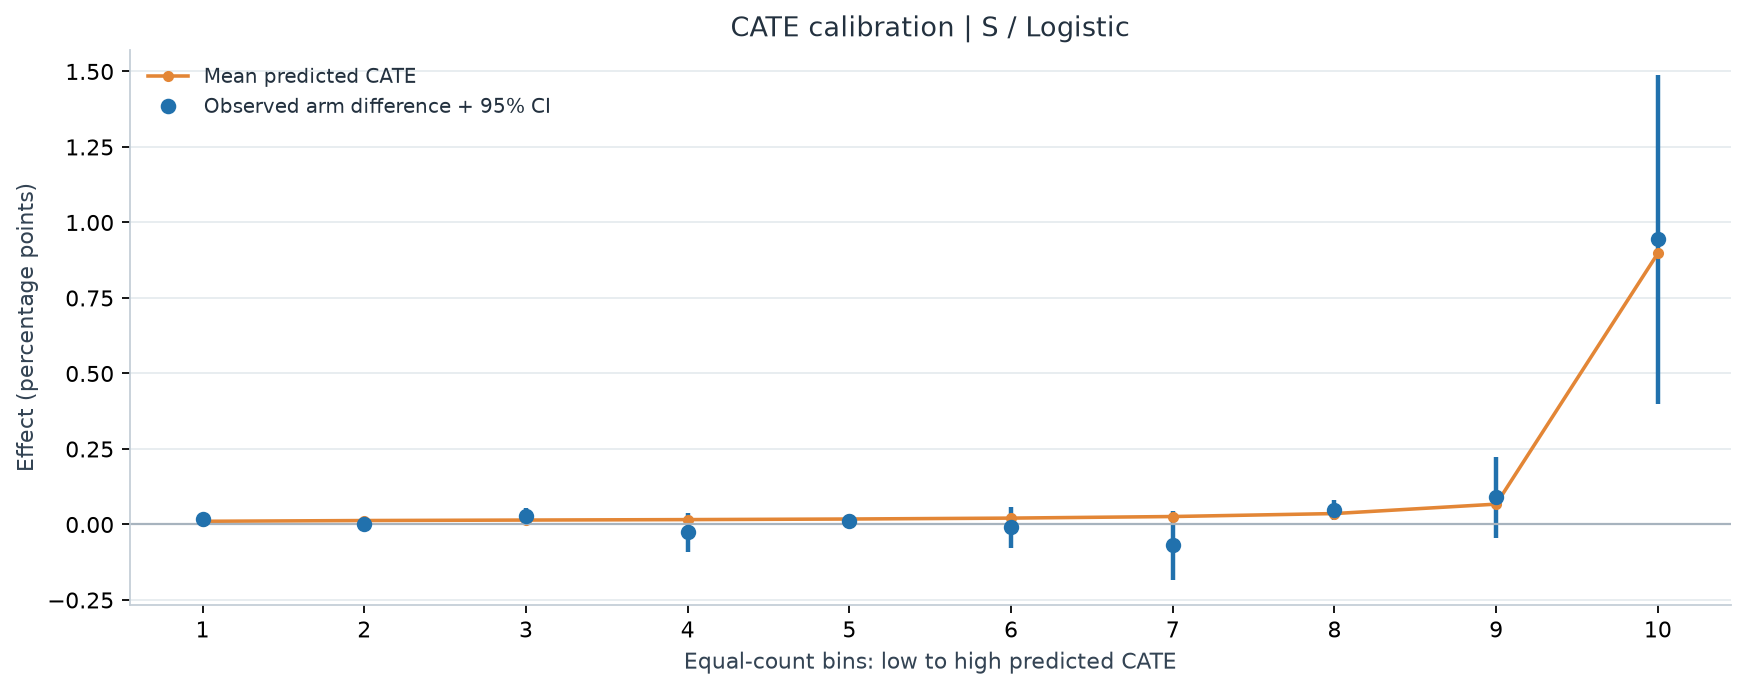

In [17]:
chosen_uplift = manifest['selection']['selected_uplift_model']
print('Validation 冻结的最佳 uplift 候选（不一定是最终策略）:', chosen_uplift)
calibration = pd.read_csv((RUN / 'evaluation' / f'calibration_{chosen_uplift}.csv'))
display(calibration.head(12))
display(Image(filename=str(RUN / 'figures/calibration.png')))

## 模型复用与部署边界

模型定义位于 models.py，训练与冻结选择位于 training_validation.py。已训练模型保存在当前结果目录的 .joblib 文件中；只加载本项目可信文件。

~~~python
from criteo_uplift.models import make_uplift_model
model = make_uplift_model('x', 'xgboost', 'xgboost', random_state=42, n_estimators=150)
model.fit(train[FEATURES], train.treatment, train.conversion)
tau = model.predict(new_users[FEATURES])
~~~

对新特征文件生成离线预算名单的入口是 score_policy.py。它不重新训练或重新选型；输入至少包含 f0–f11，输入文件保持只读，输出不得写入 data/。

Pipeline 和结果文件的完整映射见 ../docs/PROJECT_PIPELINE.md 与 ../docs/RESULTS_GUIDE.md。

## 04 · 冻结策略的离线评价

## 本页要回答什么

在 validation 已经冻结策略后，各候选策略在 test 上的 20% 预算估计值是多少？相对随机策略和 response propensity 的差值及区间如何？

## 代码导航

- 主流程阶段 6：run_pipeline.py 的 run()。
- 测试集评价入口：criteo_uplift/evaluation.py 的 evaluate_test_set()。
- 策略预算值和配对区间：criteo_uplift/evaluation.py 的 evaluate_policies()、metrics.py 的 ranking_confidence_intervals()。
- 结果文件：test_policies.csv、test_ranking.csv、curves.csv、ranking_intervals.csv、evaluation/ate_summary.csv（scope=test）、predictions.npz。

这里读取冻结实验的结果，不重新训练模型，也不根据 test 结果重新选策略。通用指标推导请查 DSDAHANDBOOK；本页重点看策略结果、比较基线和不确定性边界。

## 先冻结策略，再评价 test

最终策略在 validation 上选出并写入 selection.json。test 的作用是评价已经冻结的候选方案，不是再选一次赢家。即使另一个模型在 test 上点估计更高，也不能回头改选并将其当成独立验证。

“每十万人增量”以全部符合条件的待选用户为分母；20% 预算意味着每十万人选出 20,000 人。

In [18]:
selection = json.loads(((RUN / 'models' / 'selection.json')).read_text())
print('Validation 冻结的最终策略:', selection['selected_policy'])
policies = pd.read_csv((RUN / 'evaluation' / 'test_policies.csv'))
main = policies[np.isclose(policies.budget, selection['primary_budget'])].copy()
main = main.sort_values('incremental_per_100k', ascending=False)

print('主预算下的策略点估计与 95% CI（每十万待选人）')
display(main[['policy', 'n_selected', 'incremental_per_100k', 'ci_low', 'ci_high']])

print('相对基线的成对差值与 95% CI')
display(main[[
    'policy', 'vs_random_per_100k', 'vs_random_ci_low', 'vs_random_ci_high',
    'vs_propensity_per_100k', 'vs_propensity_ci_low', 'vs_propensity_ci_high'
]])

Validation 冻结的最终策略: propensity
主预算下的策略点估计与 95% CI（每十万待选人）


,policy,n_selected,incremental_per_100k,ci_low,ci_high
15,t_logistic,40000,126.328883,76.984177,170.377394
9,s_logistic,40000,123.324666,69.634569,172.808076
33,propensity,40000,117.227679,64.092311,166.214162
27,x_xgboost,40000,110.115936,58.906281,156.629384
21,t_xgboost,40000,95.352684,44.195004,139.263461
3,random,40000,24.614993,13.575185,35.216452


相对基线的成对差值与 95% CI


,policy,vs_random_per_100k,vs_random_ci_low,vs_random_ci_high,vs_propensity_per_100k,vs_propensity_ci_low,vs_propensity_ci_high
15,t_logistic,101.713890,62.756388,136.159924,9.101205,-10.334237,24.842219
9,s_logistic,98.709673,55.564416,137.869474,6.096987,-1.768486,14.614644
33,propensity,92.612686,50.016238,132.153717,0.000000,0.000000,0.000000
27,x_xgboost,85.500942,43.842376,122.426070,-7.111743,-31.513585,18.637349
21,t_xgboost,70.737691,30.346664,106.046309,-21.874995,-41.385956,-6.147873
3,random,0.000000,0.000000,0.000000,-92.612686,-132.153717,-50.016238


## 成对 bootstrap：区间应怎样阅读

**实现位置：** evaluation.py 的 evaluate_policies() 与 metrics.py 的 ranking_confidence_intervals()；测试阶段由 evaluation.py 调用。

同一次按 treatment 臂分层的重抽样用于比较策略，每次按固定分数重新选 top-k。策略差值使用成对差值分布；不要用两条独立置信区间是否重叠来判断策略差异。

当前区间条件于已拟合模型、冻结分数、固定的分配概率估计和观测臂样本量；不包含重训、模型选型、分配概率估计误差或未知用户依赖。多个辅助预算比较属于探索性分析。

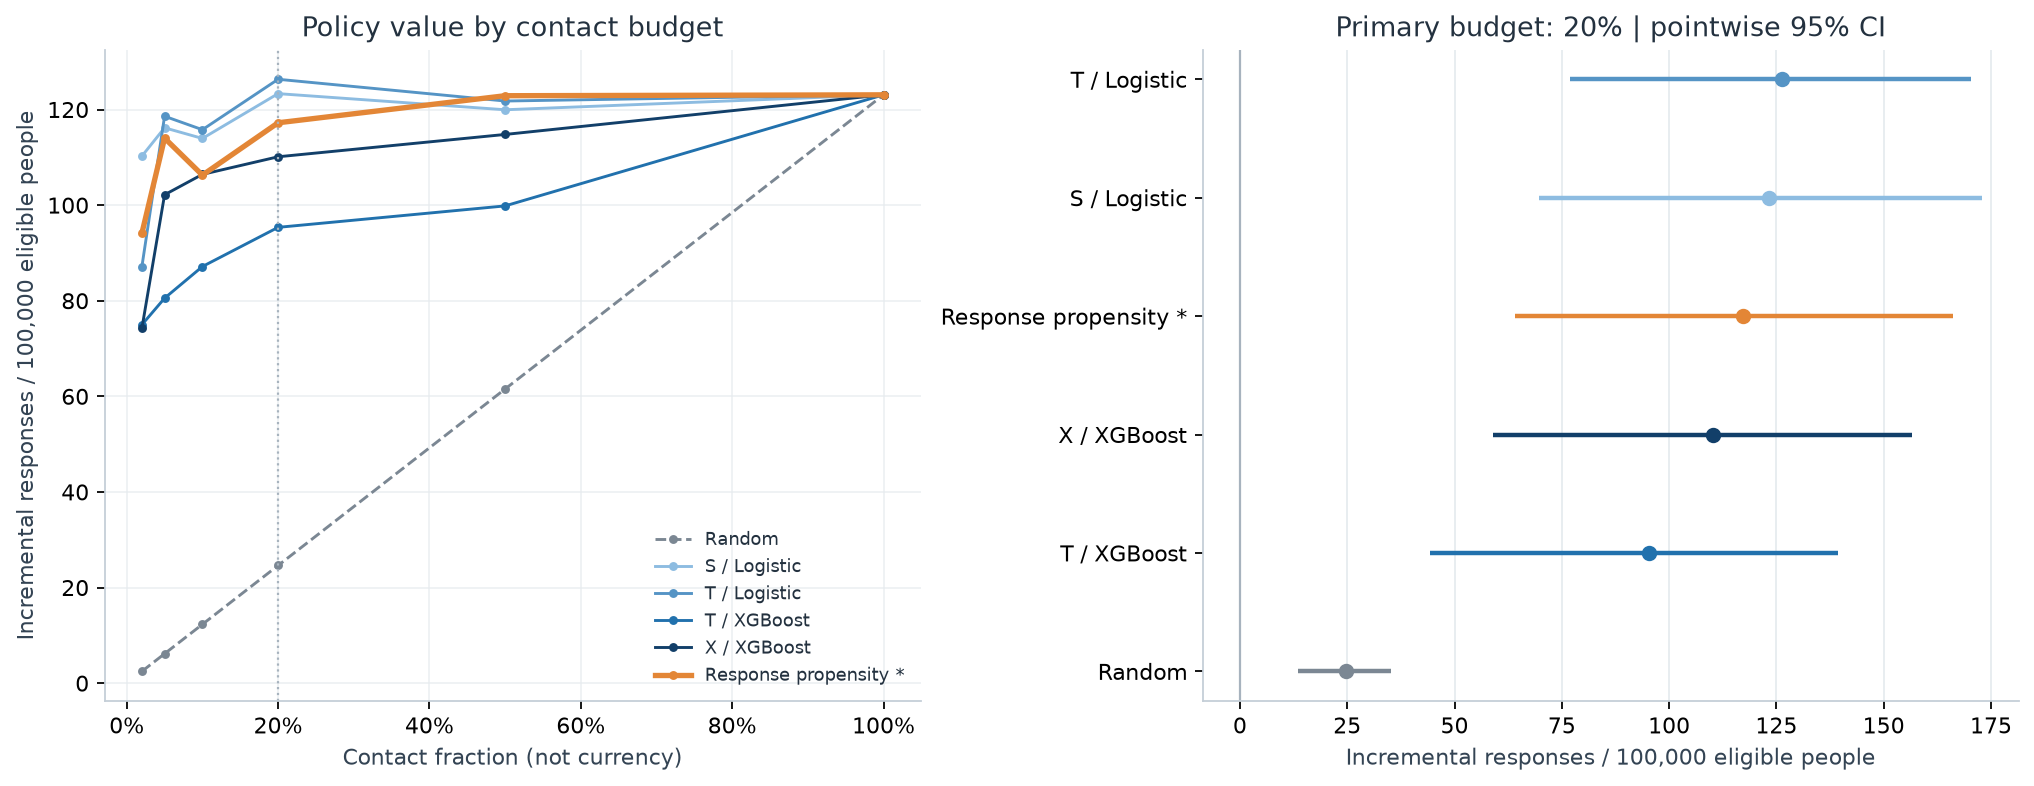

,policy,budget,incremental_per_100k,ci_low,ci_high
15,t_logistic,0.2,126.328883,76.984177,170.377394
9,s_logistic,0.2,123.324666,69.634569,172.808076
33,propensity,0.2,117.227679,64.092311,166.214162
27,x_xgboost,0.2,110.115936,58.906281,156.629384
21,t_xgboost,0.2,95.352684,44.195004,139.263461
3,random,0.2,24.614993,13.575185,35.216452


In [19]:
display(Image(filename=str(RUN / 'figures/policy.png')))

# 图展示多个预算；这里仅列主预算结果，避免再输出一张过宽的全预算表。
main_budget = selection['primary_budget']
main_budget_table = policies[np.isclose(policies.budget, main_budget)].copy()
main_budget_table = main_budget_table.sort_values('incremental_per_100k', ascending=False)
display(main_budget_table[['policy', 'budget', 'incremental_per_100k', 'ci_low', 'ci_high']])

## 本轮结论如何表达

1. 先看冻结策略在 20% 主预算下的增量估计和相对基线的成对区间。
2. 如果相对 response 的差值区间包含 0，应写“证据不足”，不要写“没有差异”，也不要强行宣称 uplift 模型胜出。
3. conversion 事件稀疏、control 臂更少，复杂模型可能不稳定；100 万行开发实验不等同于全量建模结论。
4. 这里是公开样本上的离线策略模拟，不是实际广告投放或真实收入增长。
5. 开发期稳定性、成本情景见 本笔记 Stability 与 Planning 章节；这些分析不能替代独立线上 A/B。

结果文件字段和可对外表达边界见 ../docs/RESULTS_GUIDE.md。

In [20]:
row=main[main.policy==selection['selected_policy']].iloc[0]
print(f"冻结政策 {row.policy}：每十万待选用户增量 {row.incremental_per_100k:.1f}，95% CI [{row.ci_low:.1f}, {row.ci_high:.1f}]")
print(f"相对 random 差值 {row.vs_random_per_100k:.1f}，成对95% CI [{row.vs_random_ci_low:.1f}, {row.vs_random_ci_high:.1f}]")
print('完整报告:', (RUN/'report.html').relative_to(ROOT))

冻结政策 propensity：每十万待选用户增量 117.2，95% CI [64.1, 166.2]
相对 random 差值 92.6，成对95% CI [50.0, 132.2]
完整报告: reports/published/conversion_1000000_seed42_refactored/report.html


## 下一步阅读

- 想知道 test 指标怎样计算：criteo_uplift/evaluation.py。
- 想知道测试集评价如何调用指标并写出 CSV/NPZ：criteo_uplift/evaluation.py。
- 想知道报告图表如何生成：criteo_uplift/reporting.py。

主流程与结果目录导航见 ../docs/PROJECT_PIPELINE.md；各结果文件含义见 ../docs/RESULTS_GUIDE.md。

## 指标教学核验 · 八行人工数据

以下仅验证公式实现，不是 Criteo 业务结果。所有正式指标由 metrics.py 计算。

In [21]:
from criteo_uplift.metrics import uplift_curve, ranking_metrics
from fractions import Fraction as F
t = np.array([1,0,1,0,1,0,1,0])
y = np.array([1,0,1,0,0,1,1,0])
scores = np.arange(8,0,-1)/10
curve = uplift_curve(y,t,scores,e=.5)
metrics = ranking_metrics(y,t,scores,e=.5)
display(pd.DataFrame({'rank':np.arange(1,9),'score':scores,'treatment':t,'conversion':y}))
display(curve[['n_selected', 'fraction', 'n_treatment', 'n_control', 'cumulative_lift', 'gain_plugin', 'qini_traditional', 'gain_ht']])

,rank,score,treatment,conversion
0,1,0.8,1,1
1,2,0.7,0,0
2,3,0.6,1,1
3,4,0.5,0,0
4,5,0.4,1,0
5,6,0.3,0,1
6,7,0.2,1,1
7,8,0.1,0,0


,n_selected,fraction,n_treatment,n_control,cumulative_lift,gain_plugin,qini_traditional,gain_ht
0,0,0.000,0,0,NaN,0.000000,NaN,0.00
1,1,0.125,1,0,NaN,NaN,NaN,0.25
2,2,0.250,1,1,1.000000,0.250000,0.125000,0.25
3,3,0.375,2,1,1.000000,0.375000,0.250000,0.50
4,4,0.500,2,2,1.000000,0.500000,0.250000,0.50
5,5,0.625,3,2,0.666667,0.416667,0.250000,0.50
6,6,0.750,3,3,0.333333,0.250000,0.125000,0.25
7,7,0.875,4,3,0.416667,0.364583,0.208333,0.50
8,8,1.000,4,4,0.500000,0.500000,0.250000,0.50


## 精确分数复算：独立核对浮点实现

Notebook 使用 Fraction 逐段计算曲线梯形面积，再用 assert 与 metrics.py 的结果对照。这是对实现口径的可复核检查，不是模型效果实验。

阅读时先对照 q、gain 和 qini 的各个点，再看精确分数表；相同排序使用不同的曲线定义时，面积数值可能不同，不能混用指标口径。

In [22]:
q = [F(0),F(1,4),F(3,8),F(1,2),F(5,8),F(3,4),F(7,8),F(1)]
g = [F(0),F(1,4),F(3,8),F(1,2),F(5,12),F(1,4),F(35,96),F(1,2)]
qini = [F(0),F(1,8),F(1,4),F(1,4),F(1,4),F(1,8),F(5,24),F(1,4)]
def trapezoids(x,y):
    return [(x[i]-x[i-1])*(y[i]+y[i-1])/2 for i in range(1,len(x))]
g_areas, q_areas = trapezoids(q,g), trapezoids(q,qini)
display(pd.DataFrame({'q_left':list(map(str,q[:-1])),'q_right':list(map(str,q[1:])),
                      'gain_trapezoid':list(map(str,g_areas)),'qini_trapezoid':list(map(str,q_areas))}))
exact = {'auuc_plugin':sum(g_areas),'auuc_plugin_centered':sum(g_areas)-F(1,4),
         'qini_score_traditional':sum(q_areas)-F(1,8), 'auuc_ht':F(3,8),'qini_ht':F(1,8)}
assert exact['auuc_plugin'] == F(81,256)
assert exact['qini_score_traditional'] == F(19,384)
for name,value in exact.items(): np.testing.assert_allclose(metrics[name],float(value),rtol=0,atol=1e-14)
display(pd.DataFrame([{'metric':k,'exact':str(v),'decimal':float(v),'code':metrics[k]} for k,v in exact.items()]))

,q_left,q_right,gain_trapezoid,qini_trapezoid
0,0,1/4,1/32,1/64
1,1/4,3/8,5/128,3/128
2,3/8,1/2,7/128,1/32
3,1/2,5/8,11/192,1/32
4,5/8,3/4,1/24,3/128
5,3/4,7/8,59/1536,1/48
6,7/8,1,83/1536,11/384


,metric,exact,decimal,code
0,auuc_plugin,81/256,0.316406,0.316406
1,auuc_plugin_centered,17/256,0.066406,0.066406
2,qini_score_traditional,19/384,0.049479,0.049479
3,auuc_ht,3/8,0.375000,0.375000
4,qini_ht,1/8,0.125000,0.125000


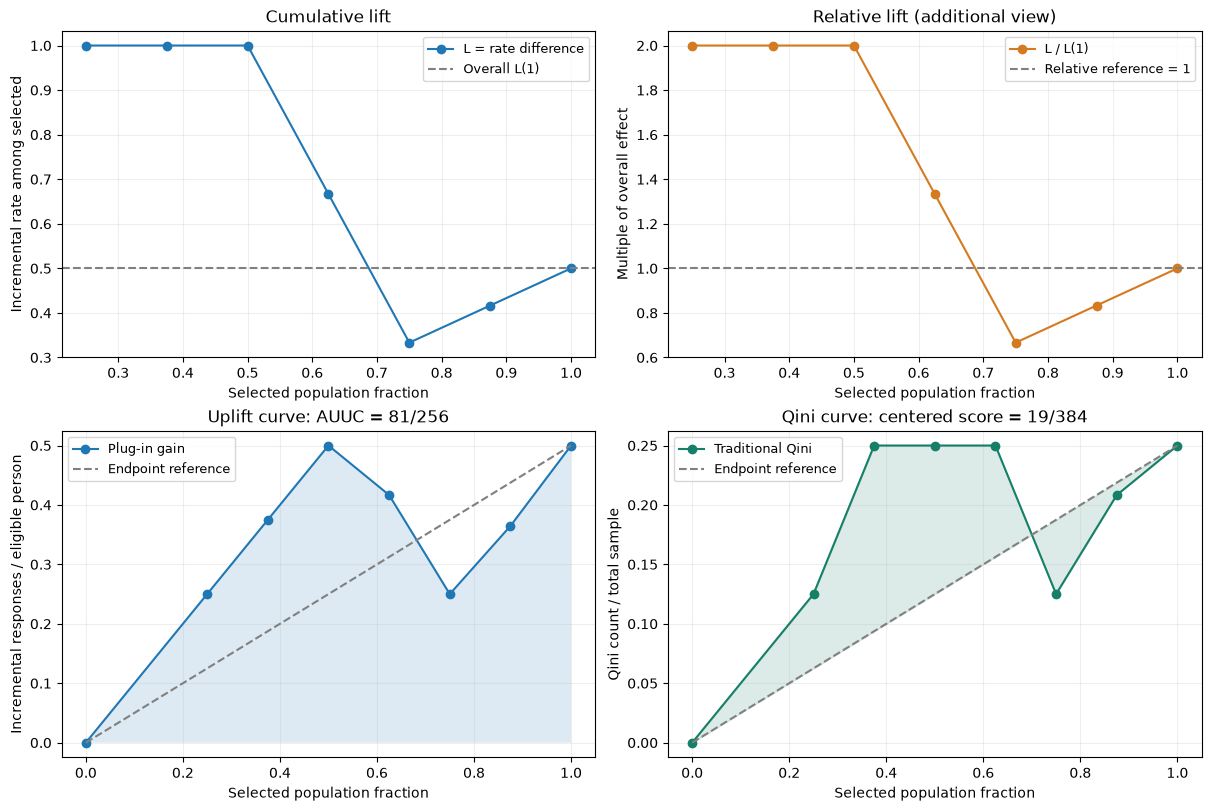

In [23]:
fig,axes=plt.subplots(2,2,figsize=(12,8),layout='constrained')
axes[0,0].plot(curve.fraction,curve.cumulative_lift,'o-',label='L = rate difference')
axes[0,0].axhline(.5,ls='--',color='gray',label='Overall L(1)')
axes[0,0].set(title='Cumulative lift',ylabel='Incremental rate among selected')
axes[0,1].plot(curve.fraction,curve.relative_lift,'o-',color='#d47a20',label='L / L(1)')
axes[0,1].axhline(1,ls='--',color='gray',label='Relative reference = 1')
axes[0,1].set(title='Relative lift (additional view)',ylabel='Multiple of overall effect')
axes[1,0].plot(list(map(float,q)),list(map(float,g)),'o-',label='Plug-in gain')
axes[1,0].fill_between(list(map(float,q)),list(map(float,g)),alpha=.15)
axes[1,0].plot([0,1],[0,.5],'--',color='gray',label='Endpoint reference')
axes[1,0].set(title='Uplift curve: AUUC = 81/256',ylabel='Incremental responses / eligible person')
axes[1,1].plot(list(map(float,q)),list(map(float,qini)),'o-',color='#167f67',label='Traditional Qini')
axes[1,1].plot([0,1],[0,.25],'--',color='gray',label='Endpoint reference')
axes[1,1].fill_between(list(map(float,q)),list(map(float,qini)),[float(x/4) for x in q],alpha=.15,color='#167f67')
axes[1,1].set(title='Qini curve: centered score = 19/384',ylabel='Qini count / total sample')
for ax in axes.flat:
    ax.set_xlabel('Selected population fraction');ax.legend(fontsize=9);ax.grid(alpha=.2)

plt.show()

## HT 与 plug-in 曲线为什么分别保留

本项目同时保存 HT 与传统 plug-in 估计口径，原因是有限样本下两者的前缀估计方式不同。这里通过同一组人工数据并排画图，检查代码实现是否按预定定义计算；它不是用来判断哪个模型在真实 Criteo 数据上更好。

实现位置仍是 metrics.py 的 uplift_curve() 与 ranking_metrics()。

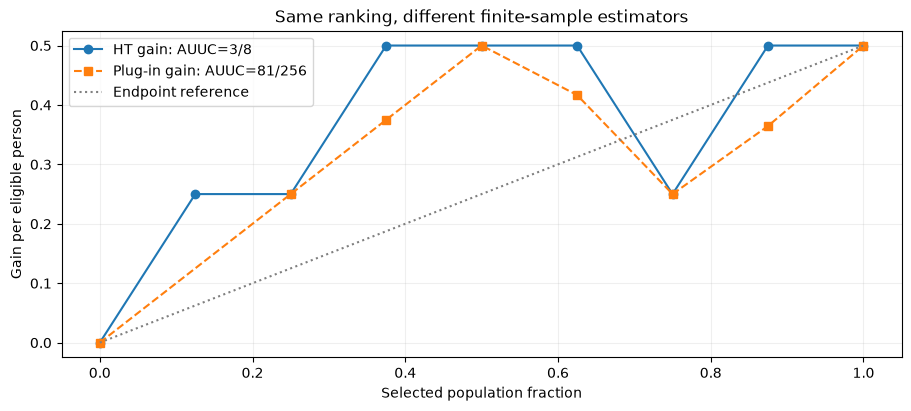

In [24]:
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
ax.plot(curve.fraction,curve.gain_ht,'o-',label='HT gain: AUUC=3/8')
ax.plot(list(map(float,q)),list(map(float,g)),'s--',label='Plug-in gain: AUUC=81/256')
ax.plot([0,1],[0,.5],':',color='gray',label='Endpoint reference')
ax.set(xlabel='Selected population fraction',ylabel='Gain per eligible person',title='Same ranking, different finite-sample estimators')
ax.legend();ax.grid(alpha=.2)
plt.show()

## Stability · 排除 Test 后检查稳定性

采用原设计的种子 17/29/83、嵌套训练比例 25%/50%/100%，并比较行分层划分与匿名特征分组划分。每个配置的 Validation 只用于本次开发实验。

这些实验共享开发样本，均值、标准差与选择频率是描述性统计，不是新的独立验证。相同匿名特征不是用户标识；之前已经看过历史 Test，排除其行不能消除分析者已有知识。

In [25]:
ST = RUN / 'stability'
report = json.loads((ST / 'report.json').read_text())
long = pd.read_csv(ST / 'longmetrics.csv')
agg = pd.read_csv(ST / 'aggregate.csv')
audit = pd.read_csv(ST / 'split_audit.csv')

display({
    key: report[key]
    for key in [
        'experiments', 'fitted_models', 'development_n',
        'old_test_n_excluded', 'all_old_test_row_overlaps_zero',
        'all_group_split_feature_overlaps_zero'
    ]
})
audit_columns = [
    'split_method', 'train_n', 'validation_n',
    'train_old_test_overlap', 'validation_old_test_overlap',
    'feature_group_overlap'
]
missing_columns = [column for column in audit_columns if column not in audit.columns]
if missing_columns:
    raise ValueError(f"split_audit.csv 缺少必需字段：{', '.join(missing_columns)}")
if 'row_overlap' in audit.columns:
    audit_columns.append('row_overlap')
display(audit[audit_columns])

cols = [
    'split_method', 'training_fraction', 'policy',
    'incremental_per_100k_mean', 'incremental_per_100k_std',
    'vs_propensity_per_100k_mean', 'train_control_events_min',
    'train_control_events_max'
]
display(agg[cols].sort_values(['split_method', 'training_fraction', 'policy']))

{'experiments': 12,
 'fitted_models': 48,
 'development_n': 800000,
 'old_test_n_excluded': 200000,
 'all_old_test_row_overlaps_zero': True,
 'all_group_split_feature_overlaps_zero': True}

,split_method,train_n,validation_n,train_old_test_overlap,validation_old_test_overlap,feature_group_overlap,row_overlap
0,row_stratified,149999,200000,0,0,938,0
1,row_stratified,299999,200000,0,0,1857,0
2,row_stratified,600000,200000,0,0,3677,0
3,feature_group,599941,200059,0,0,0,0
4,row_stratified,149999,200000,0,0,941,0
5,row_stratified,299999,200000,0,0,1911,0
6,row_stratified,600000,200000,0,0,3688,0
7,feature_group,600072,199928,0,0,0,0
8,row_stratified,149998,200000,0,0,920,0
9,row_stratified,299999,200000,0,0,1893,0


,split_method,training_fraction,policy,incremental_per_100k_mean,incremental_per_100k_std,vs_propensity_per_100k_mean,train_control_events_min,train_control_events_max
23,feature_group,1.00,propensity,146.032995,5.484177,0.000000,163,169
18,feature_group,1.00,random,28.732907,0.570554,-117.300088,163,169
19,feature_group,1.00,s_logistic,148.792021,5.349990,2.759026,163,169
20,feature_group,1.00,t_logistic,134.838641,4.288820,-11.194355,163,169
21,feature_group,1.00,t_xgboost,127.301159,6.073088,-18.731836,163,169
22,feature_group,1.00,x_xgboost,119.100833,3.467040,-26.932163,163,169
5,row_stratified,0.25,propensity,126.593822,5.401909,0.000000,40,41
0,row_stratified,0.25,random,25.060479,0.386261,-101.533343,40,41
1,row_stratified,0.25,s_logistic,124.768235,3.799729,-1.825587,40,41
2,row_stratified,0.25,t_logistic,98.262244,20.575630,-28.331578,40,41


,policy,auuc_plugin,auuc_ht,qini_score_traditional,qini_ht
0,s_logistic,0.001132,0.001196,0.000444,0.000580
1,t_logistic,0.001148,0.001210,0.000458,0.000595
2,t_xgboost,0.000912,0.000972,0.000256,0.000357
3,x_xgboost,0.001057,0.001099,0.000379,0.000484
4,propensity,0.001137,0.001198,0.000448,0.000583


,metric,policy,estimate,ci_low,ci_high,vs_propensity,vs_propensity_ci_low,vs_propensity_ci_high
0,auuc_ht,s_logistic,0.001196,0.000637,0.001650,-0.000003,-0.000023,0.000017
1,qini_ht,s_logistic,0.000580,0.000302,0.000808,-0.000003,-0.000023,0.000017
2,auuc_plugin,s_logistic,0.001132,0.000565,0.001590,-0.000006,-0.000030,0.000016
3,auuc_plugin_centered,s_logistic,0.000516,0.000238,0.000749,-0.000006,-0.000030,0.000016
4,qini_score_traditional,s_logistic,0.000444,0.000204,0.000644,-0.000004,-0.000025,0.000014
5,auuc_ht,t_logistic,0.001210,0.000720,0.001611,0.000012,-0.000130,0.000183
6,qini_ht,t_logistic,0.000595,0.000372,0.000804,0.000012,-0.000130,0.000183
7,auuc_plugin,t_logistic,0.001148,0.000649,0.001574,0.000011,-0.000128,0.000181
8,auuc_plugin_centered,t_logistic,0.000533,0.000314,0.000745,0.000011,-0.000128,0.000181
9,qini_score_traditional,t_logistic,0.000458,0.000270,0.000641,0.000010,-0.000108,0.000155


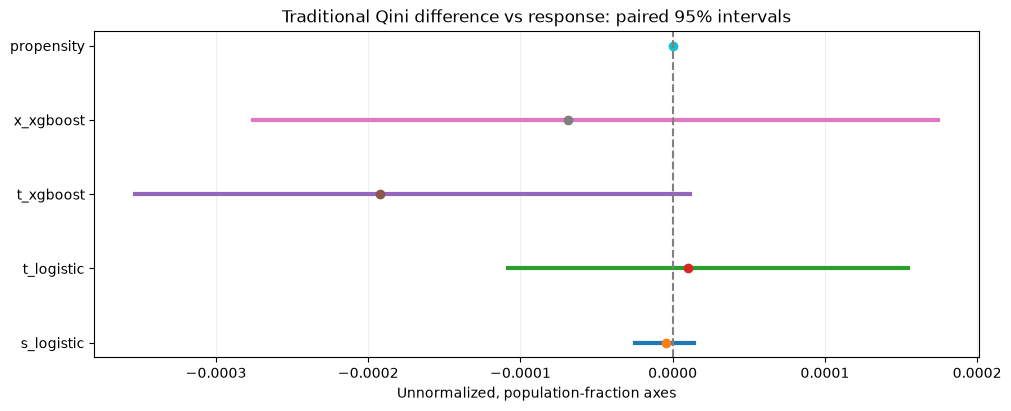

In [26]:
MET = RUN / 'evaluation'
ranking = pd.read_csv(MET / 'test_ranking.csv')
intervals = pd.read_csv(MET / 'ranking_intervals.csv')

ranking_cols = [c for c in [
    'policy', 'auuc_plugin', 'auuc_ht', 'qini_score_traditional',
    'qini_ht', 'relative_lift'
] if c in ranking.columns]
display(ranking[ranking_cols])

interval_cols = [c for c in [
    'metric', 'policy', 'estimate', 'ci_low', 'ci_high',
    'vs_propensity', 'vs_propensity_ci_low', 'vs_propensity_ci_high'
] if c in intervals.columns]
display(intervals[interval_cols])

chosen = intervals[intervals.metric == 'qini_score_traditional'].copy()
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for i, row in enumerate(chosen.itertuples()):
    ax.plot([row.vs_propensity_ci_low, row.vs_propensity_ci_high], [i, i], lw=3)
    ax.plot(row.vs_propensity, i, 'o')
ax.axvline(0, color='gray', ls='--')
ax.set_yticks(range(len(chosen)), chosen.policy)
ax.set(title='Traditional Qini difference vs response: paired 95% intervals', xlabel='Unnormalized, population-fraction axes')
ax.grid(axis='x', alpha=.2)
plt.show()

## Score Policy · 有新人群 X 才能执行打分

独立入口 `score_policy.py` 接收 f0–f11，不要求 T 或 Y。它加载冻结策略，分块计算分数，按预算选择 Top-k，输出 `source_row_id`、`score`、`selected`。

当前未提供真实外部 X-only 数据，因此没有新人群部署结果。只有 X 时不能计算观测 ATE、ATT 或 ITT；打分也不等于投放。

```bash
python score_policy.py --run artifacts/conversion_1000000_seed42_refactored \
  --input /path/to/new_users.csv \
  --output artifacts/conversion_1000000_seed42_refactored/business/score_policy_scores.csv --budget 0.2
```

In [27]:
display(json.loads((RUN / 'business/score_policy_status.json').read_text()))

{'status': 'not_run',
 'reason': '未提供外部 X-only 数据，尚未执行真实新人群打分。',
 'entrypoint': 'score_policy.py'}

## Planning · 明确假设之后做规划

`plan_policy_ab()` 由假设的线上基线率、MDE、分配比、alpha 和 power 推算两组样本量。`cost_value_scenario()` 将离线增量按假设的每次转化价值和触达成本换算经济价值。

这里沿用原项目的教学参数。所有经济数字都依赖固定价值、固定成本和效果可迁移假设，不能说成 Criteo 已验证的真实收入；固定假设换算的区间也不包含成本或价值的不确定性。

In [28]:
assumptions = json.loads((RUN / 'business/assumptions.json').read_text())
display(assumptions)
display(pd.read_csv(RUN / 'business/hypothetical_ab_plans.csv'))
display(pd.read_csv(RUN / 'business/hypothetical_cost_scenarios.csv'))

{'hypothetical': True,
 'parameters': {'p0': 0.003,
  'absolute_mdes': [0.00015, 0.0003, 0.0006],
  'allocation_ratio': 1.0,
  'alpha': 0.05,
  'power': 0.8,
  'values_per_conversion': [1.0, 5.0, 10.0],
  'contact_costs': [0.001, 0.01, 0.05],
  'eligible_n': 100000},
 'frozen_selected_policy': 'propensity',
 'budget': 0.2,
 'effect_source': '../evaluation/test_policies.csv',
 'interpretation': '假设固定价值、触达成本与效果可迁移；不是 Criteo 真实线上收入或 ROI。'}

,p0_assumed,p1_assumed,absolute_mde,relative_mde,alpha_two_sided,target_power,allocation_ratio_A_over_B,n_policy_B,n_policy_A,n_total,contact_fraction_each_policy,contacts_B,contacts_A,approximate_achieved_power,assumption
0,0.003,0.00315,0.00015,0.05,0.05,0.8,1.0,2138763,2138763,4277526,0.2,427752,427752,0.800001,Hypothetical policy CVRs on all eligible users...
1,0.003,0.00330,0.00030,0.10,0.05,0.8,1.0,547690,547690,1095380,0.2,109538,109538,0.800001,Hypothetical policy CVRs on all eligible users...
2,0.003,0.00360,0.00060,0.20,0.05,0.8,1.0,143421,143421,286842,0.2,28684,28684,0.800003,Hypothetical policy CVRs on all eligible users...


,incremental_per_100k,eligible_n,budget,contacts,value_per_conversion_assumed,contact_cost_assumed,incremental_conversions,gross_incremental_value,contact_cost_total,net_incremental_value,net_ci_low_conditional,net_ci_high_conditional,break_even_contact_cost,assumption
0,117.227679,100000,0.2,20000,1.0,0.001,117.227679,117.227679,20.0,97.227679,44.092311,146.214162,0.005861,"Hypothetical constant value/cost, fixed effect..."
1,117.227679,100000,0.2,20000,1.0,0.010,117.227679,117.227679,200.0,-82.772321,-135.907689,-33.785838,0.005861,"Hypothetical constant value/cost, fixed effect..."
2,117.227679,100000,0.2,20000,1.0,0.050,117.227679,117.227679,1000.0,-882.772321,-935.907689,-833.785838,0.005861,"Hypothetical constant value/cost, fixed effect..."
3,117.227679,100000,0.2,20000,5.0,0.001,117.227679,586.138394,20.0,566.138394,300.461555,811.070810,0.029307,"Hypothetical constant value/cost, fixed effect..."
4,117.227679,100000,0.2,20000,5.0,0.010,117.227679,586.138394,200.0,386.138394,120.461555,631.070810,0.029307,"Hypothetical constant value/cost, fixed effect..."
5,117.227679,100000,0.2,20000,5.0,0.050,117.227679,586.138394,1000.0,-413.861606,-679.538445,-168.929190,0.029307,"Hypothetical constant value/cost, fixed effect..."
6,117.227679,100000,0.2,20000,10.0,0.001,117.227679,1172.276788,20.0,1152.276788,620.923109,1642.141620,0.058614,"Hypothetical constant value/cost, fixed effect..."
7,117.227679,100000,0.2,20000,10.0,0.010,117.227679,1172.276788,200.0,972.276788,440.923109,1462.141620,0.058614,"Hypothetical constant value/cost, fixed effect..."
8,117.227679,100000,0.2,20000,10.0,0.050,117.227679,1172.276788,1000.0,172.276788,-359.076891,662.141620,0.058614,"Hypothetical constant value/cost, fixed effect..."


## 项目收束与面试表达

1. **业务目标**：固定触达预算下增加转化，区分响应概率与增量效果。
2. **可信流程**：全量检查和审计、均匀抽样、60/20/20 分层划分、分组诊断、Train 拟合、Validation 冻结、Test 评价。
3. **方法证据**：ATE/ITT 说明平均分配效果；CATE 排序用于定向；HT 策略值与配对 Bootstrap 描述预算收益及差异的不确定性。
4. **稳健性**：排除 Test 后检查随机种子、训练规模、特征分组划分；不把开发期赢家当成新独立证据。
5. **业务落地边界**：独立打分接口已经具备；真实投放仍需要新数据、明确成本与新的线上 A/B。

简历只写真实完成的方法、规模与结果。相对 response 的区间包含零应表述为证据不足；不能写“提升了真实收入”。最终策略始终以 Validation 冻结记录为准。

In [29]:
selection = manifest['selection']
results = pd.read_csv(RUN / 'evaluation/test_policies.csv')
chosen = results[(results.policy == selection['selected_policy']) & np.isclose(results.budget, selection['primary_budget'])]
print('冻结策略：', selection['selected_policy'], '｜最佳 uplift 候选：', selection['selected_uplift_model'])
display(chosen)
print('完整报告：', (RUN / 'report.html').relative_to(ROOT))

冻结策略： propensity ｜最佳 uplift 候选： s_logistic


,policy,budget,n_selected,selected_fraction,incremental_per_100k,ci_low,ci_high,vs_random_per_100k,vs_random_ci_low,vs_random_ci_high,vs_propensity_per_100k,vs_propensity_ci_low,vs_propensity_ci_high,bootstrap_replicates
33,propensity,0.2,40000,0.2,117.227679,64.092311,166.214162,92.612686,50.016238,132.153717,0.0,0.0,0.0,200


完整报告： reports/published/conversion_1000000_seed42_refactored/report.html
